# Selected momentum-strategy comparison

This notebook studies five selected strategies: conventional momentum, lagged-RV volatility-timed momentum, factor momentum, lagged-RV volatility-timed factor momentum, and factor momentum from lagged-RV-timed factors. It focuses on their time-series behavior, performance, and spanning relationships. All reported t-statistics use monthly Newey–West standard errors with 12 lags.

In [1]:
# 0. Libraries and project modules
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))

from config import FACTOR_MOMENTUM_PANEL, HAC_LAGS, MANAGED_FACTORS
from factor_momentum_horse_race import (
    equal_volatility_panel, pairwise_strategy_spanning, strategy_performance_table,
)
from plots import (
    plot_selected_full_return_series, plot_selected_strategy_correlation,
    plot_selected_strategy_paths, plot_selected_subperiod_paths,
)
from selected_strategy_analysis import (
    SELECTED_PLOT_LABELS, SELECTED_SHORT_LABELS, SELECTED_STRATEGIES,
    build_selected_strategy_panel, equal_subperiod_statistics,
    native_performance_table, risk_management_table,
    subperiod_display_tables,
)
from utils import format_estimate_with_t

## 1. Strategies and common sample

The two lagged-RV factor-momentum constructions differ in timing order. **Lagged-RV volatility-timed factor momentum** first constructs factor momentum and then times the aggregate portfolio. **Factor momentum from lagged-RV-timed factors** first times each factor and then forms the factor-momentum signals and portfolio.

Native-scale statistics preserve each stored construction. For comparative figures and regressions, all returns are additionally rescaled by one positive constant to conventional momentum's volatility over the common sample. This ex-post scale is descriptive and is not an implementable target-volatility rule.

In [2]:
# 1. Load and validate the selected-strategy panel
managed_factors = pd.read_parquet(MANAGED_FACTORS)
factor_momentum = pd.read_parquet(FACTOR_MOMENTUM_PANEL)
analysis = build_selected_strategy_panel(managed_factors, factor_momentum)
ff5_sample = analysis.dropna(
    subset=['ff5_mkt_rf', 'ff5_smb', 'ff5_hml', 'rmw', 'cma']
)
print(
    f"Common strategy sample: {analysis.date.min():%Y-%m} to "
    f"{analysis.date.max():%Y-%m} ({len(analysis):,} months)."
)
print(
    f"FF5-based alpha sample: {ff5_sample.date.min():%Y-%m} to "
    f"{ff5_sample.date.max():%Y-%m} ({len(ff5_sample):,} months)."
)

Common strategy sample: 1927-08 to 2026-07 (1,188 months).
FF5-based alpha sample: 1963-07 to 2026-07 (757 months).


## 2. Full-sample return paths

The four panels put all strategies and the market excess-return benchmark at conventional momentum's full-sample volatility. Cumulative wealth therefore compares reward per unit of realized volatility rather than native leverage. Drawdowns show the path-dependent losses experienced at that same comparison scale. The market is repeated in both strategy groups as a common reference.

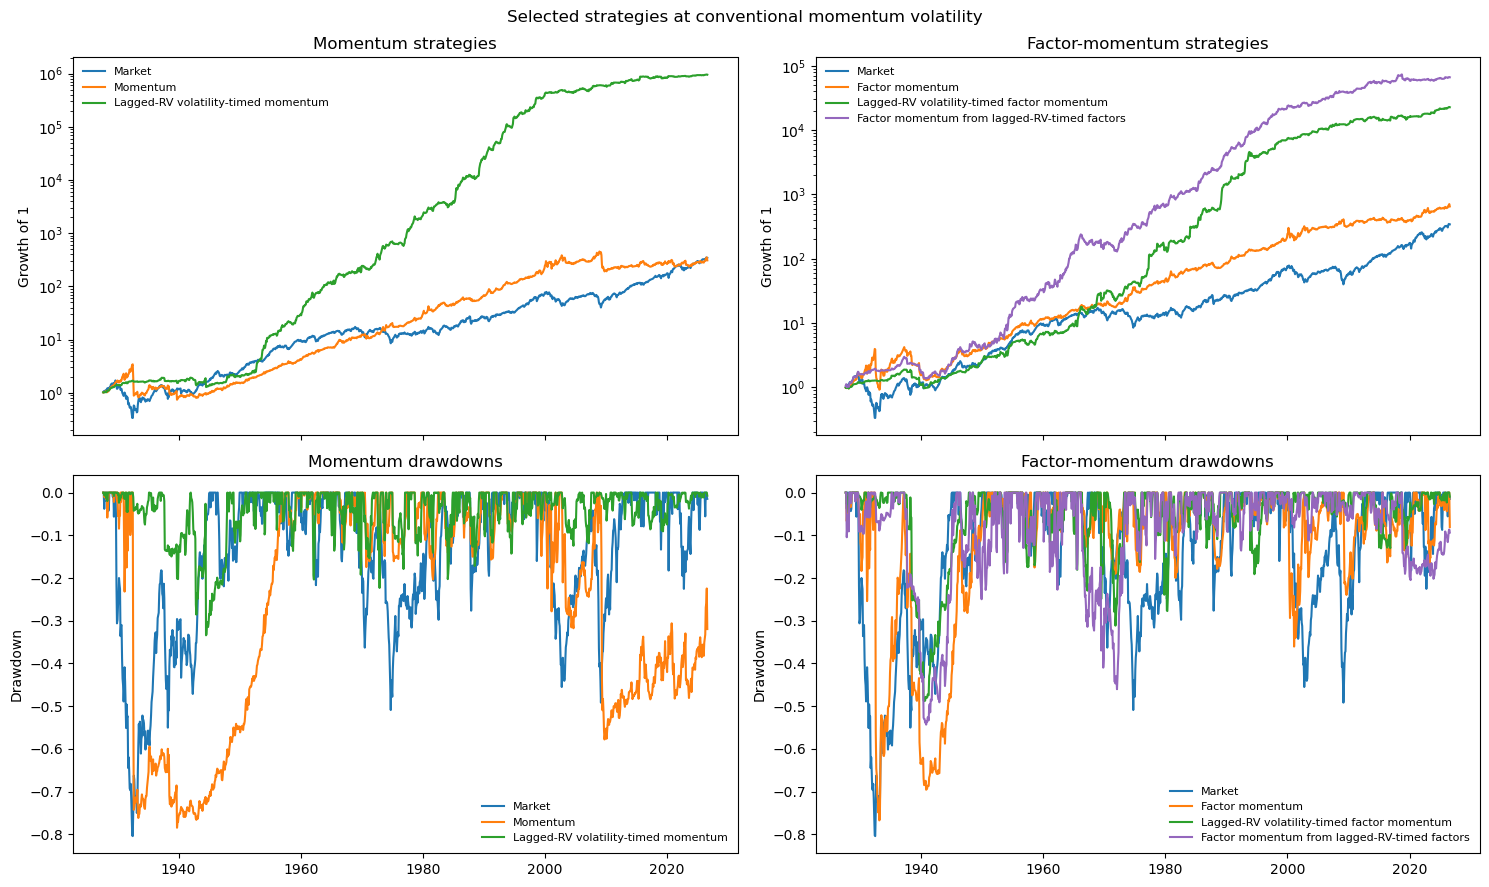

In [3]:
selected_scaled, comparison_scales = equal_volatility_panel(
    analysis, [*SELECTED_STRATEGIES, 'mkt_rf'], target_column='mom'
)
plot_selected_strategy_paths(selected_scaled, SELECTED_PLOT_LABELS);

## 3. Full-sample performance

The first table reports native-scale performance, including the monthly mean, median, and standard deviation. Every return and alpha is stated in percent; means, medians, standard deviations, and alphas are monthly. Thus, a monthly mean of 1.231 denotes an average return of 1.231% per month. The compounded annual equivalent is `(1 + monthly mean)^12 - 1`; it annualizes the average month and is not the realized geometric CAGR. The second table uses conventional-momentum volatility for comparable mean and alpha magnitudes. Parentheses contain Newey–West(12) t-statistics. A blank t-statistic is shown when the dependent return itself appears in the factor model, making its alpha zero by construction.

In [4]:
# 3. Native performance and equal-volatility factor-model alphas
native_performance = native_performance_table(analysis, SELECTED_STRATEGIES)
native_display = native_performance[[
    'strategy', 'mean_monthly_pct', 'median_pct', 'std_monthly_pct',
    'compounded_annual_equivalent_pct', 'annualized_sharpe',
]].rename(columns={
    'strategy': 'Strategy', 'mean_monthly_pct': 'Monthly mean (%)',
    'median_pct': 'Monthly median (%)',
    'std_monthly_pct': 'Monthly std (%)',
    'compounded_annual_equivalent_pct': 'Compounded annual equivalent (%)',
    'annualized_sharpe': 'Annualized SR',
})
display(native_display.round(3))

performance = strategy_performance_table(
    analysis, SELECTED_STRATEGIES, HAC_LAGS, target_column='mom'
)
performance_display = pd.DataFrame({
    'Strategy': performance['strategy'],
    'Monthly mean (%) [NW t]': format_estimate_with_t(
        performance, 'mean_monthly_pct', 'mean_t_nw12'),
    'Monthly CAPM alpha (%) [NW t]': format_estimate_with_t(
        performance, 'capm_alpha_monthly_pct', 'capm_alpha_t_nw12'),
    'Monthly FF3 alpha (%) [NW t]': format_estimate_with_t(
        performance, 'ff3_alpha_monthly_pct', 'ff3_alpha_t_nw12'),
    'Monthly FF5 alpha (%) [NW t]': format_estimate_with_t(
        performance, 'ff5_alpha_monthly_pct', 'ff5_alpha_t_nw12'),
})
display(performance_display)

,Strategy,Monthly mean (%),Monthly median (%),Monthly std (%),Compounded annual equivalent (%),Annualized SR
0,Momentum,0.609,0.800,4.704,7.563,0.449
1,Lagged-RV volatility-timed momentum,1.231,0.498,4.552,15.817,0.937
2,Factor momentum,0.357,0.417,2.529,4.374,0.490
3,Lagged-RV volatility-timed factor momentum,0.505,0.190,2.501,6.227,0.699
4,Factor momentum from lagged-RV-timed factors,0.452,0.273,2.030,5.564,0.772


,Strategy,Monthly mean (%) [NW t],Monthly CAPM alpha (%) [NW t],Monthly FF3 alpha (%) [NW t],Monthly FF5 alpha (%) [NW t]
0,Momentum,0.609 (4.79),0.815 (7.80),0.932 (8.35),0.749 (4.24)
1,Lagged-RV volatility-timed momentum,1.272 (7.16),1.282 (7.29),1.325 (7.47),1.370 (6.02)
2,Factor momentum,0.665 (5.25),0.700 (5.29),0.721 (5.06),0.577 (4.11)
3,Lagged-RV volatility-timed factor momentum,0.949 (6.02),0.897 (5.82),0.893 (6.01),0.999 (4.61)
4,Factor momentum from lagged-RV-timed factors,1.048 (6.86),0.981 (6.58),0.993 (6.66),0.927 (5.20)


## 4. Full-sample risk management

Risk statistics use each strategy's native stored return scale. The empirical 5% VaR is reported as a positive monthly loss and equals the negative of the 5th-percentile return. Empirical 5% Expected Shortfall (ES) is the positive average loss among months at or below that threshold. Both are historical estimates and impose no distributional assumption. Maximum drawdown is the worst peak-to-trough cumulative loss and is therefore a path-risk measure. The return quantiles are shown separately so the full monthly distribution remains visible.

In [5]:
risk = risk_management_table(analysis, SELECTED_STRATEGIES)
risk_display = risk[[
    'strategy', 'quantile_05_pct', 'quantile_25_pct',
    'quantile_75_pct', 'quantile_95_pct',
    'empirical_var_05_loss_pct', 'empirical_es_05_loss_pct',
    'skewness', 'excess_kurtosis', 'maximum_drawdown_pct',
]].rename(columns={
    'strategy': 'Strategy',
    'quantile_05_pct': '5th percentile return (%)',
    'quantile_25_pct': '25th percentile return (%)',
    'quantile_75_pct': '75th percentile return (%)',
    'quantile_95_pct': '95th percentile return (%)',
    'empirical_var_05_loss_pct': 'Empirical 5% VaR: loss (%)',
    'empirical_es_05_loss_pct': 'Empirical 5% ES: loss (%)',
    'skewness': 'Skewness', 'excess_kurtosis': 'Excess kurtosis',
    'maximum_drawdown_pct': 'Maximum drawdown (%)',
})
display(risk_display.round(3))

,Strategy,5th percentile return (%),25th percentile return (%),75th percentile return (%),95th percentile return (%),Empirical 5% VaR: loss (%),Empirical 5% ES: loss (%),Skewness,Excess kurtosis,Maximum drawdown (%)
0,Momentum,-6.062,-0.960,2.930,6.432,6.062,11.835,-3.021,27.449,-78.437
1,Lagged-RV volatility-timed momentum,-4.332,-0.574,2.378,8.975,4.332,7.826,1.227,9.901,-32.282
2,Factor momentum,-3.261,-0.522,1.409,3.671,3.261,5.758,-0.958,25.806,-49.834
3,Lagged-RV volatility-timed factor momentum,-2.255,-0.325,0.996,3.862,2.255,4.180,3.489,38.119,-28.532
4,Factor momentum from lagged-RV-timed factors,-2.354,-0.460,1.286,3.824,2.354,4.079,0.401,4.528,-27.607


## 5. Full-sample directional spanning and correlations

Each spanning cell reports monthly alpha with its Newey–West(12) t-statistic in parentheses. Rows are dependent strategies and columns are candidate spanning strategies; the diagonal is intentionally blank. The correlation heatmap reports full-sample Pearson correlations among monthly strategy returns. Correlation describes comovement but does not replace the directional spanning regressions.

Spanning strategy,Mom,VT-Mom,FM,FM → VT-LRV,VT-LRV factors → FM
Dependent strategy,,,,,
Mom,,0.034 (0.28),0.171 (1.60),0.344 (2.67),0.231 (1.81)
VT-Mom,0.997 (6.22),,1.081 (6.52),0.881 (6.12),0.635 (5.40)
FM,0.264 (2.24),0.299 (2.22),,0.267 (2.15),0.172 (1.55)
FM → VT-LRV,0.779 (5.11),0.424 (3.25),0.671 (4.50),,0.334 (3.50)
VT-LRV factors → FM,0.828 (5.86),0.274 (2.03),0.735 (5.40),0.490 (4.21),


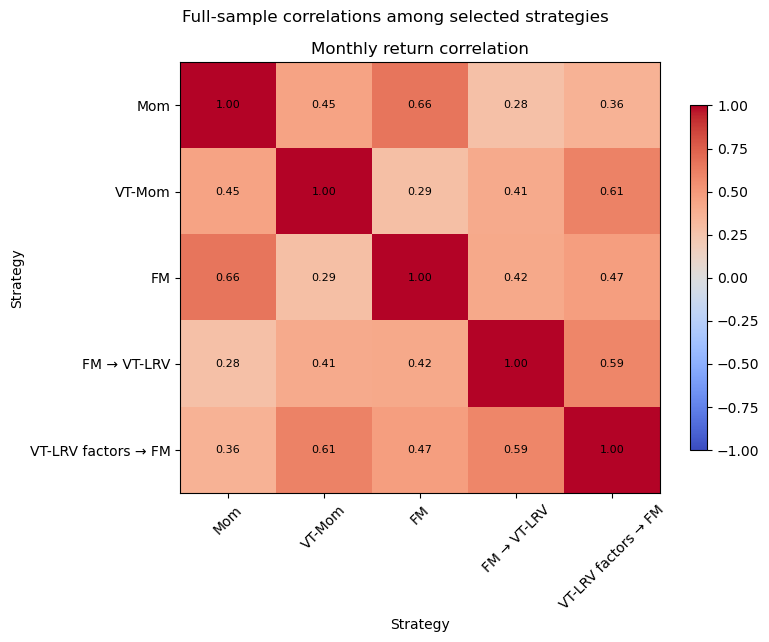

In [6]:
pairwise = pairwise_strategy_spanning(
    analysis, SELECTED_STRATEGIES, HAC_LAGS,
    short_labels=SELECTED_SHORT_LABELS, target_column='mom',
)
pairwise['Alpha (NW t)'] = format_estimate_with_t(
    pairwise, 'alpha_monthly_pct', 'alpha_t_nw12'
)
short_order = list(SELECTED_SHORT_LABELS.values())
pairwise_display = pairwise.pivot(
    index='dependent_short', columns='spanning_short', values='Alpha (NW t)'
).reindex(index=short_order, columns=short_order)
pairwise_display.index.name = 'Dependent strategy'
pairwise_display.columns.name = 'Spanning strategy'
display(pairwise_display.fillna(''))
plot_selected_strategy_correlation(analysis, SELECTED_SHORT_LABELS);

## 6. Equal-length subperiod performance and risk

The 1,188-month common sample is divided mechanically into three consecutive periods of 396 months. Breakpoints are therefore independent of strategy outcomes. The first figure shows the full monthly-return history and marks these periods. Each period then has its own cumulative-wealth and drawdown figure; cumulative wealth restarts at one, while the full-sample equal-volatility comparison constants remain fixed. Native-scale performance and risk-management tables follow each figure. This is descriptive subperiod evidence, not an out-of-sample test: the existing strategy constructions and normalization constants are not re-estimated within each period.

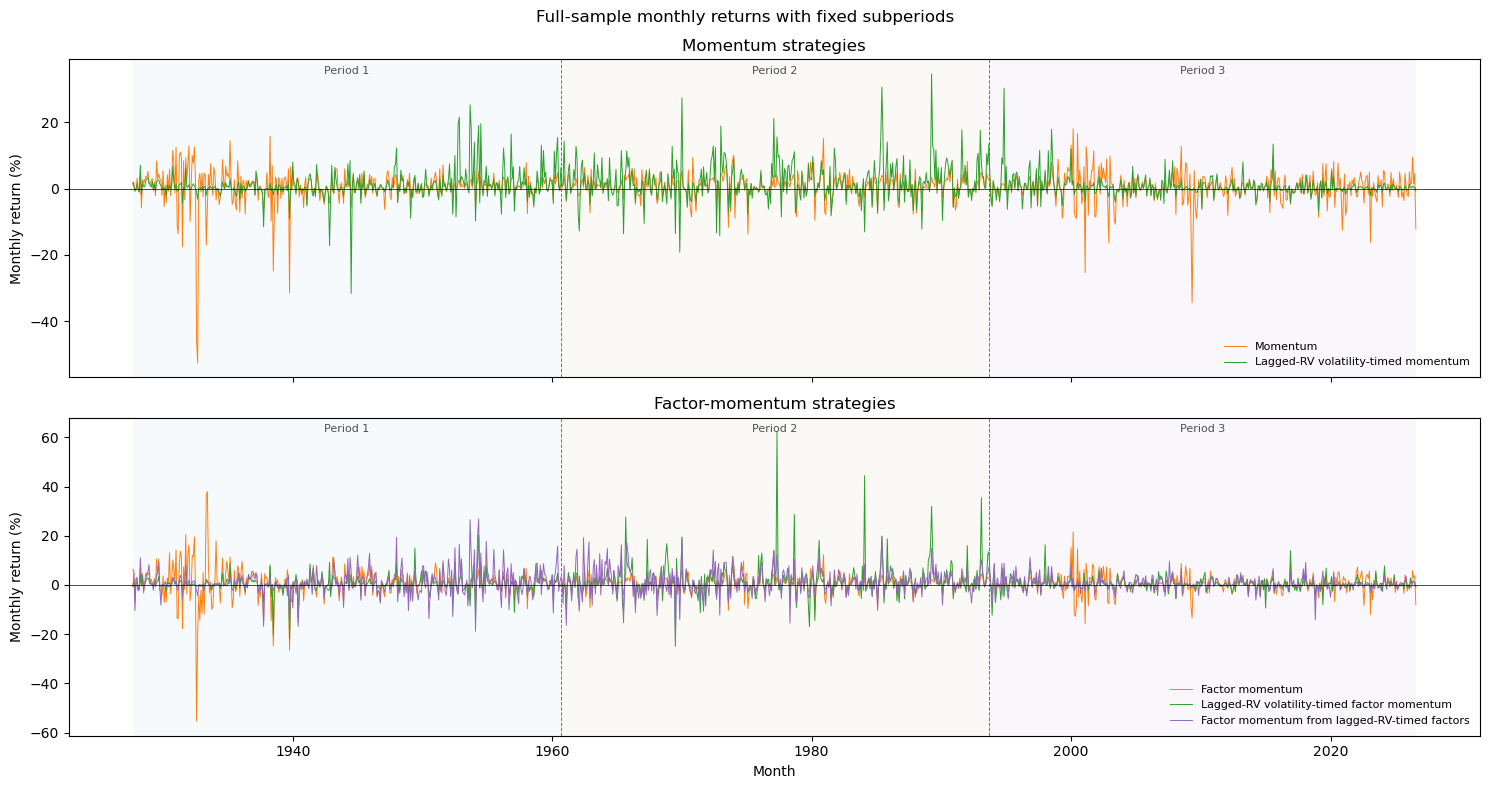

In [7]:
subperiods = equal_subperiod_statistics(
    analysis, SELECTED_STRATEGIES, n_periods=3
)
subperiod_ranges = (
    subperiods[[
        'period_number', 'period', 'start', 'end', 'observations'
    ]]
    .drop_duplicates()
    .sort_values('period_number')
)
plot_selected_full_return_series(
    selected_scaled, SELECTED_PLOT_LABELS, subperiod_ranges
);

### 6.1 Period 1: August 1927–July 1960

Performance


,Strategy,Monthly mean (%),Monthly median (%),Monthly std (%),Compounded annual equivalent (%),Annualized SR
0,Momentum,0.592,0.955,5.664,7.337,0.362
1,Lagged-RV volatility-timed momentum,1.014,0.504,4.357,12.874,0.806
2,Factor momentum,0.470,0.580,3.555,5.785,0.458
3,Lagged-RV volatility-timed factor momentum,0.299,0.178,1.827,3.649,0.567
4,Factor momentum from lagged-RV-timed factors,0.466,0.208,2.305,5.741,0.701


Risk management


,Strategy,5th percentile (%),25th percentile (%),75th percentile (%),95th percentile (%),5% VaR: loss (%),5% ES: loss (%),Maximum drawdown (%)
0,Momentum,-5.802,-0.960,3.062,7.030,5.802,15.079,-78.437
1,Lagged-RV volatility-timed momentum,-3.202,-0.465,1.854,7.202,3.202,7.907,-32.282
2,Factor momentum,-3.975,-0.851,1.888,5.144,3.975,8.399,-49.834
3,Lagged-RV volatility-timed factor momentum,-1.804,-0.259,0.752,3.130,1.804,4.225,-28.532
4,Factor momentum from lagged-RV-timed factors,-2.825,-0.571,1.454,4.562,2.825,4.684,-27.607


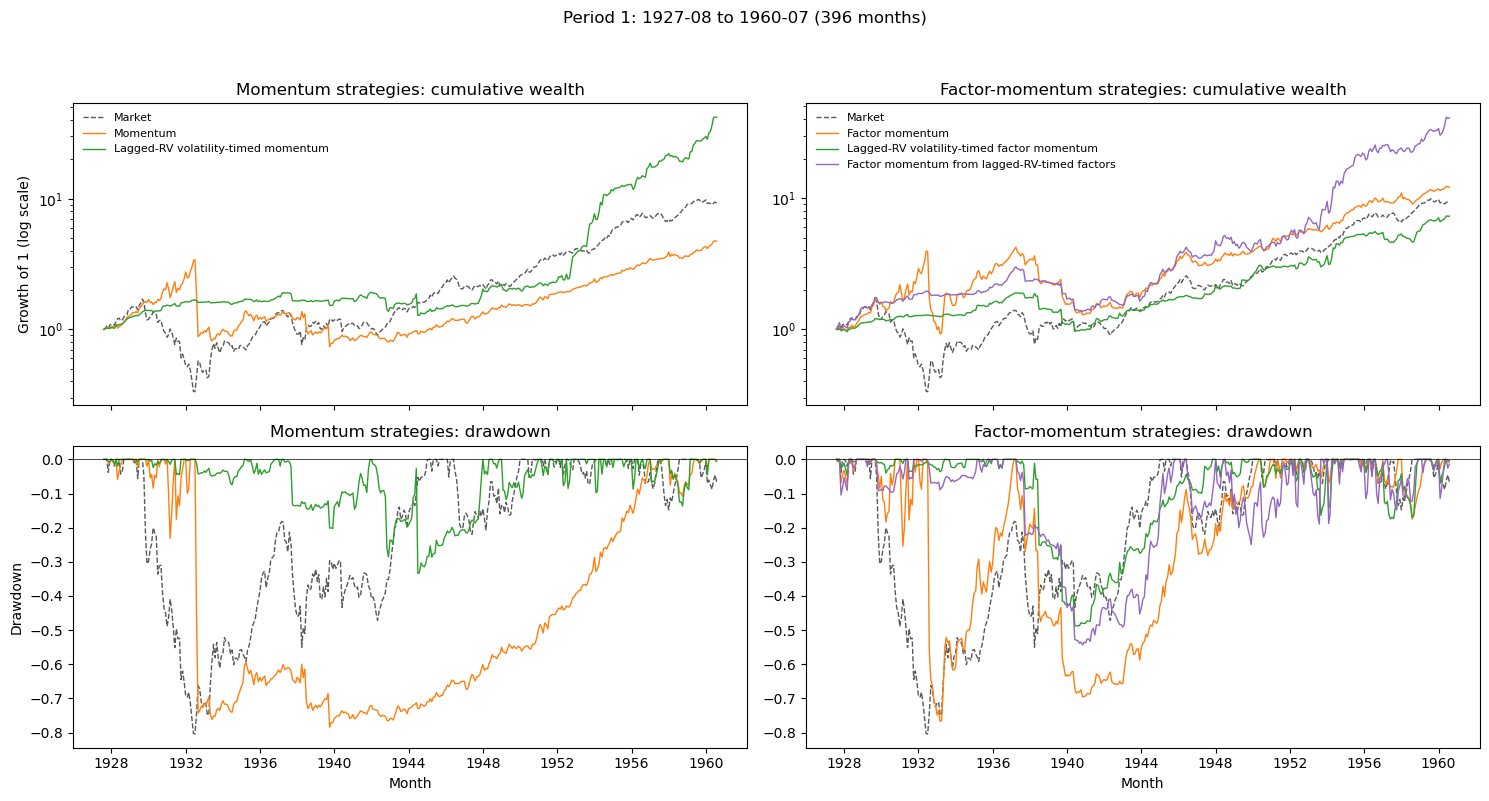

In [8]:
period = next(subperiod_ranges.loc[
    subperiod_ranges['period_number'].eq(1)
].itertuples(index=False))
plot_selected_subperiod_paths(selected_scaled, SELECTED_PLOT_LABELS, period);
period_results = subperiods.loc[subperiods['period_number'].eq(1)]
period_performance, period_risk = subperiod_display_tables(period_results)
print('Performance')
display(period_performance.round(3))
print('Risk management')
display(period_risk.round(3))

### 6.2 Period 2: August 1960–July 1993

Performance


,Strategy,Monthly mean (%),Monthly median (%),Monthly std (%),Compounded annual equivalent (%),Annualized SR
5,Momentum,0.865,0.905,3.353,10.882,0.893
6,Lagged-RV volatility-timed momentum,2.069,1.468,5.731,27.864,1.251
7,Factor momentum,0.352,0.442,1.670,4.313,0.731
8,Lagged-RV volatility-timed factor momentum,0.960,0.430,3.654,12.153,0.910
9,Factor momentum from lagged-RV-timed factors,0.652,0.636,2.385,8.114,0.948


Risk management


,Strategy,5th percentile (%),25th percentile (%),75th percentile (%),95th percentile (%),5% VaR: loss (%),5% ES: loss (%),Maximum drawdown (%)
5,Momentum,-5.495,-0.552,2.830,5.788,5.495,7.783,-20.347
6,Lagged-RV volatility-timed momentum,-6.347,-0.844,4.792,11.140,6.347,9.968,-21.626
7,Factor momentum,-2.614,-0.439,1.293,2.835,2.614,3.756,-11.111
8,Lagged-RV volatility-timed factor momentum,-2.986,-0.478,1.787,6.392,2.986,5.001,-17.587
9,Factor momentum from lagged-RV-timed factors,-2.864,-0.678,1.861,4.444,2.864,4.763,-20.938


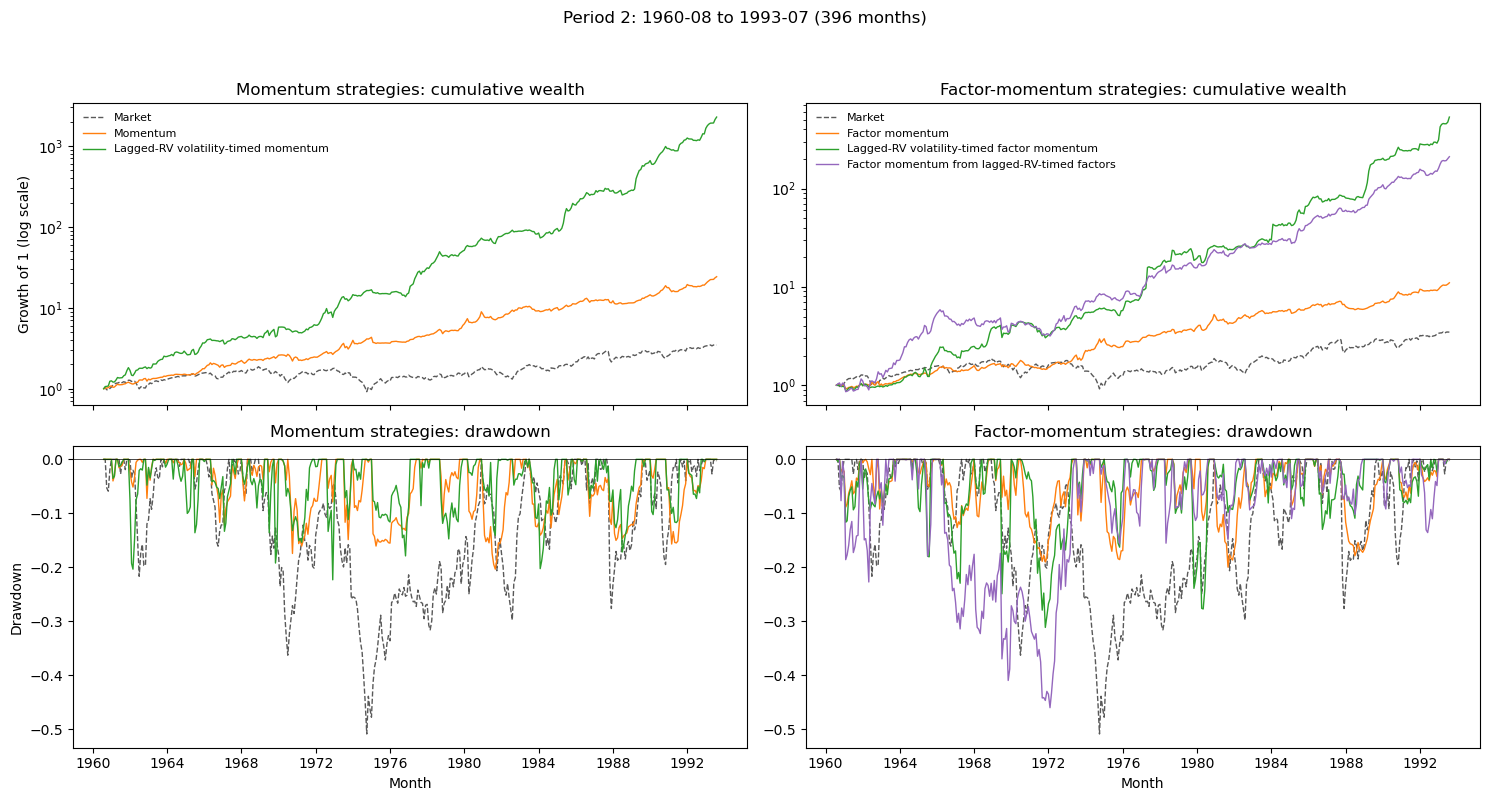

In [9]:
period = next(subperiod_ranges.loc[
    subperiod_ranges['period_number'].eq(2)
].itertuples(index=False))
plot_selected_subperiod_paths(selected_scaled, SELECTED_PLOT_LABELS, period);
period_results = subperiods.loc[subperiods['period_number'].eq(2)]
period_performance, period_risk = subperiod_display_tables(period_results)
print('Performance')
display(period_performance.round(3))
print('Risk management')
display(period_risk.round(3))

### 6.3 Period 3: August 1993–July 2026

Performance


,Strategy,Monthly mean (%),Monthly median (%),Monthly std (%),Compounded annual equivalent (%),Annualized SR
10,Momentum,0.372,0.565,4.801,4.555,0.268
11,Lagged-RV volatility-timed momentum,0.610,0.187,3.051,7.569,0.693
12,Factor momentum,0.250,0.252,1.940,3.042,0.446
13,Lagged-RV volatility-timed factor momentum,0.255,0.101,1.340,3.099,0.658
14,Factor momentum from lagged-RV-timed factors,0.238,0.177,1.141,2.895,0.723


Risk management


,Strategy,5th percentile (%),25th percentile (%),75th percentile (%),95th percentile (%),5% VaR: loss (%),5% ES: loss (%),Maximum drawdown (%)
10,Momentum,-7.825,-1.538,2.882,6.975,7.825,12.339,-57.776
11,Lagged-RV volatility-timed momentum,-3.226,-0.528,1.262,5.243,3.226,4.697,-13.856
12,Factor momentum,-2.964,-0.476,1.214,2.994,2.964,4.706,-20.312
13,Lagged-RV volatility-timed factor momentum,-1.437,-0.264,0.653,2.418,1.437,2.564,-10.265
14,Factor momentum from lagged-RV-timed factors,-1.431,-0.294,0.665,2.358,1.431,2.288,-9.067


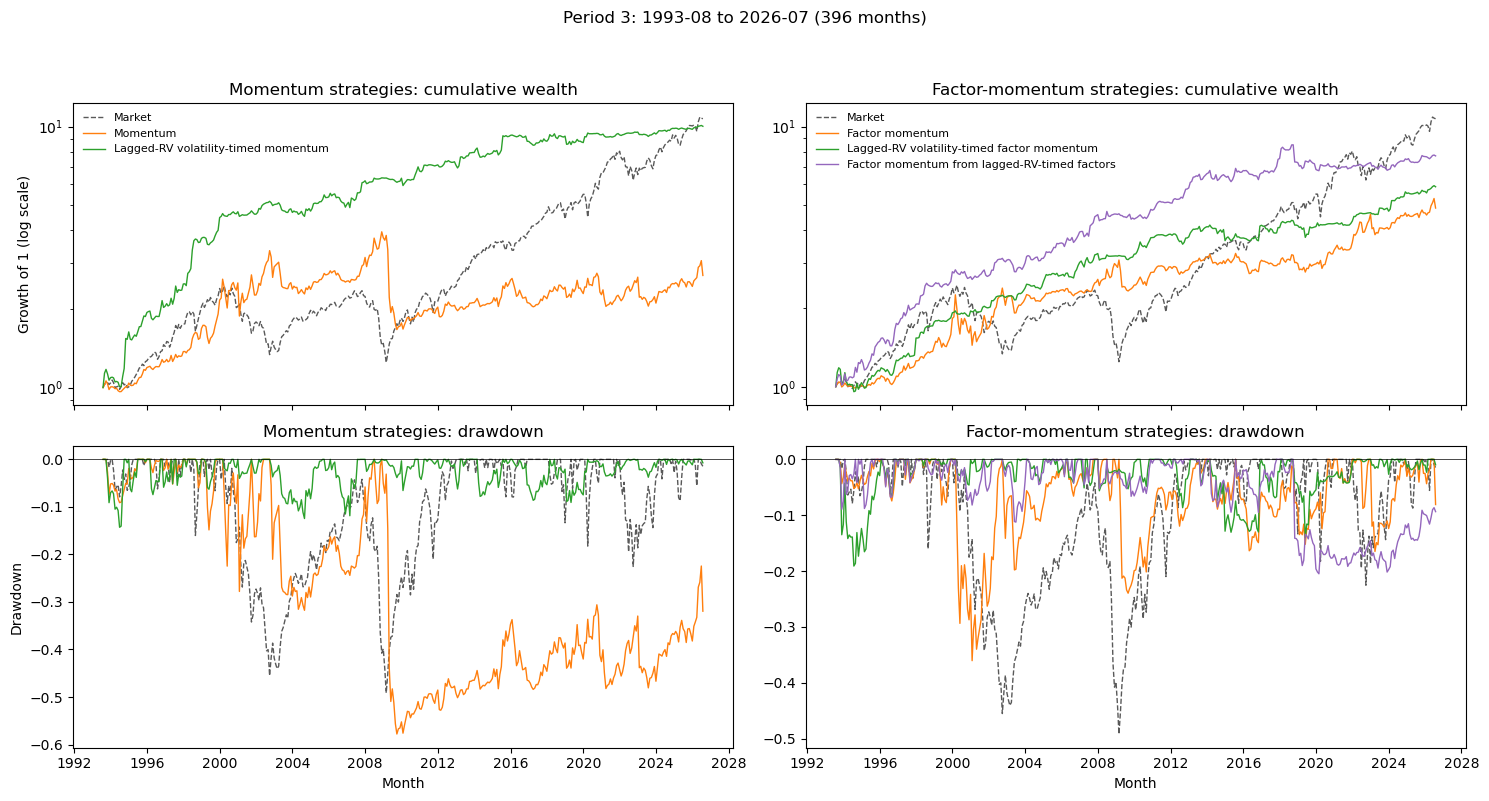

In [10]:
period = next(subperiod_ranges.loc[
    subperiod_ranges['period_number'].eq(3)
].itertuples(index=False))
plot_selected_subperiod_paths(selected_scaled, SELECTED_PLOT_LABELS, period);
period_results = subperiods.loc[subperiods['period_number'].eq(3)]
period_performance, period_risk = subperiod_display_tables(period_results)
print('Performance')
display(period_performance.round(3))
print('Risk management')
display(period_risk.round(3))

## 7. Conclusions

- Lagged-RV volatility timing has its strongest effect on conventional momentum: its full-sample Sharpe ratio rises from 0.45 to 0.94. Native 5% VaR improves from a 6.06% to a 4.33% monthly loss, 5% ES from 11.84% to 7.83%, and maximum drawdown from −78% to −32%. Its lower median but higher upper tail also shows that the improvement is not a uniform upward shift in returns. Conventional momentum is spanned by volatility-timed momentum, but the reverse is decisively rejected.
- The volatility-timed momentum Sharpe ratio exceeds conventional momentum in all three equal-length periods (0.81 versus 0.36, 1.25 versus 0.89, and 0.69 versus 0.27). Its downside protection is clearest in the first and last periods; in the middle period, its native risk is higher because the stored timing strategy operates at a higher scale. The gain is therefore persistent in risk-adjusted terms, but not identical across eras.
- Both lagged-RV factor-momentum constructions have higher Sharpe ratios than original factor momentum in every subperiod. Factor momentum from lagged-RV-timed factors has the highest factor-momentum Sharpe ratio in each period, the smallest full-sample ES and drawdown, and much less tail distortion than timing the aggregate portfolio. The two managed constructions nevertheless do not span one another, so timing order remains economically relevant.
- The latest period has lower native means for every selected strategy, so the full-sample magnitudes are not representative of every era. These descriptive subperiods support persistence without constituting an out-of-sample test. Notebook 06 examines why lagged-RV timing improves conventional momentum much more than it improves the other individual factors.